In [16]:
# Import and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)
sns.set_style('whitegrid')

df = pd.read_csv('/content/Telco-Customer-Churn.csv')
print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
# Cell 2 — Structure, types, and missing values
df.info()
print("\n--- Missing values per column ---")
print(df.isnull().sum())
print("\n--- Target balance ---")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


/tmp/ipykernel_2482/1036980548.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1,1],


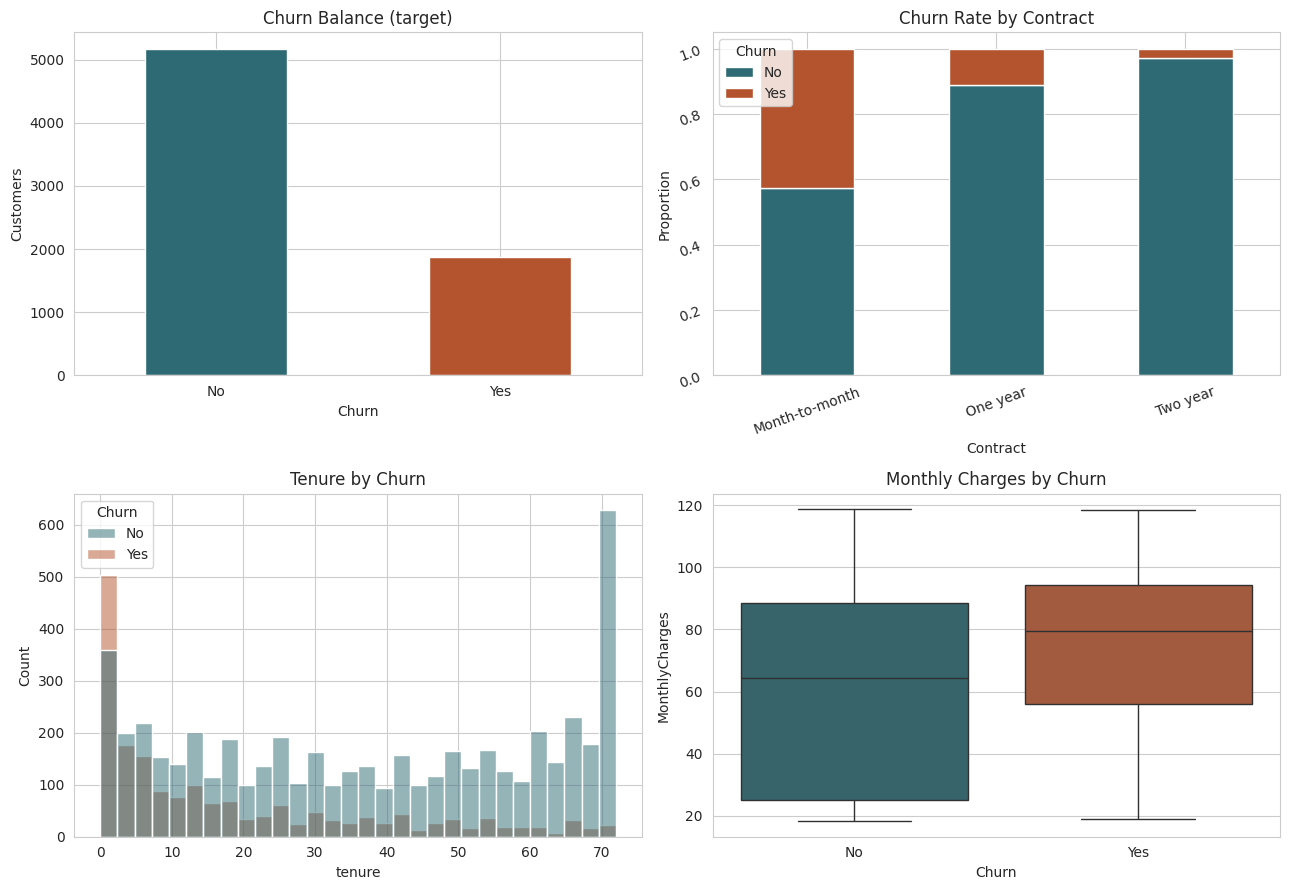

In [19]:
# Cell 3 — Visual EDA
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Overall churn balance
df['Churn'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#2d6a73','#b4542f'])
axes[0,0].set_title('Churn Balance (target)')
axes[0,0].set_ylabel('Customers'); axes[0,0].tick_params(rotation=0)

# 2. Churn by contract type
pd.crosstab(df['Contract'], df['Churn'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[0,1], color=['#2d6a73','#b4542f'])
axes[0,1].set_title('Churn Rate by Contract'); axes[0,1].tick_params(rotation=20)
axes[0,1].set_ylabel('Proportion')

# 3. Tenure distribution by churn
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=axes[1,0],
             palette=['#2d6a73','#b4542f'])
axes[1,0].set_title('Tenure by Churn')

# 4. Monthly charges by churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1,1],
            palette=['#2d6a73','#b4542f'])
axes[1,1].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.show()

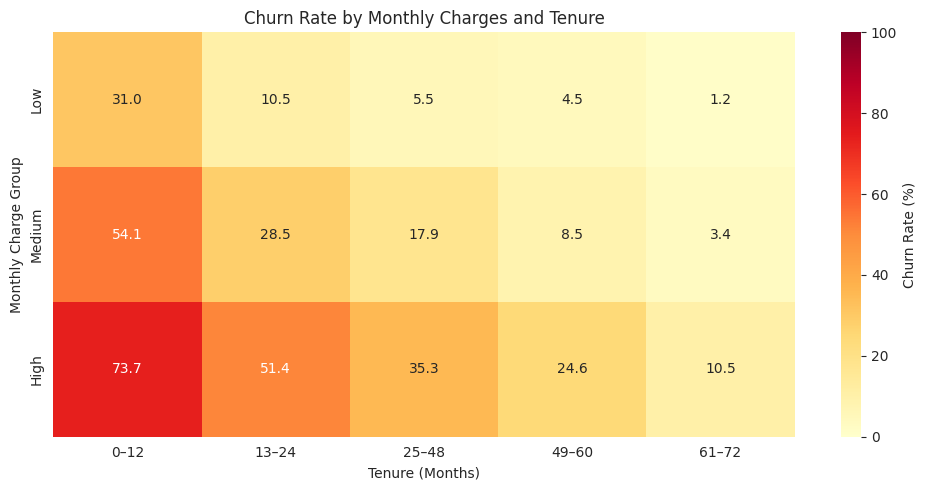

In [22]:

df_plot = df.copy()

df_plot['TenureGroup'] = pd.cut(
    df_plot['tenure'],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=['0–12', '13–24', '25–48', '49–60', '61–72']
)

df_plot['ChargeGroup'] = pd.qcut(
    df_plot['MonthlyCharges'],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)

churn_rate = df_plot.pivot_table(
    index='ChargeGroup',
    columns='TenureGroup',
    values='Churn',
    aggfunc=lambda x: (x == 'Yes').mean(),
    observed=False
) * 100

plt.figure(figsize=(10, 5))
sns.heatmap(
    churn_rate,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Churn Rate by Monthly Charges and Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charge Group')
plt.tight_layout()
plt.show()

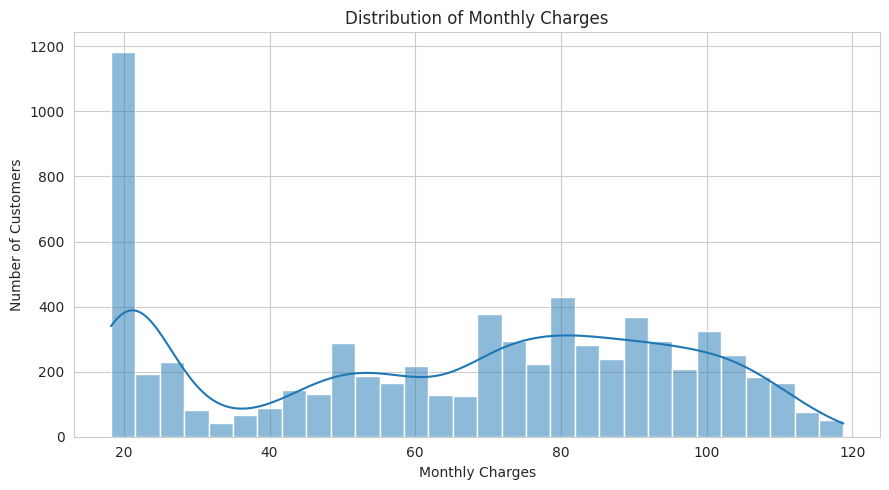

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [25]:
#Data preparation

# 1. Fix TotalCharges: it's text, with 11 blanks for brand-new customers
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Blanks found in TotalCharges:", df['TotalCharges'].isnull().sum())

# Those 11 are tenure=0 customers, so total billed is 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. Drop the ID column (useless for prediction)
df = df.drop('customerID', axis=1)

# 3. Encode target: Yes=1 (churned), No=0 (stayed)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4. One-hot encode all remaining categorical columns
df_encoded = pd.get_dummies(df, drop_first=True)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Blanks found in TotalCharges: 11
Shape after encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False
